In [2]:
from spacenet.point_patterns.helpers.compute_contributions import compute_contributions
from spacenet.point_patterns.helpers.compute_contributions_parallel import compute_contributions_parallel   
from spacenet.point_patterns.helpers.spatial_bootstrap import spatial_bootstrap
from spacenet.point_patterns.helpers.is_connected_filter import is_connected_filter
from spacenet.helpers.node_node_distance import node_node_distance  
from spacenet.point_patterns.helpers.polynomial_kernel_bandwidth_scale import polynomial_kernel_bandwidth_scale

import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import squidpy as sq
from scipy.ndimage import gaussian_filter
from skimage.color import label2rgb
from skimage.draw import ellipse
from skimage.measure import label, regionprops, regionprops_table
from skimage.transform import rotate
import warnings

from scipy.stats import kruskal
import scikit_posthocs as sp
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from skimage.segmentation import expand_labels, watershed
import os
import spacenet as sn
import random

import warnings
warnings.filterwarnings('ignore')


from spacenet.point_patterns.helpers.polynomial_kernel_bandwidth_scale import polynomial_kernel_bandwidth_scale

/home/jshemons/.conda/envs/cellpose-spatial/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/home/jshemons/.conda/envs/cellpose-spatial/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'show_progress_bar' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)


In [ ]:
### This function is utilizes this documentation as inspiration: https://www.spacenet-python.com/latest/examples.html
### It takes my high attention patches (HAP) (or integrated gradients) from the ABMIL heatmap then compares them to 100 randomly sampled patches
### Then it asks "are these patches more or less clustered than my own" across all 100 random samples. In summary, its 100 random patches
### v. the one high attention patch. The p-value is signifies the number of random patches that are less clustered than the HAP.
### This is done for all HAP. A visualization of a single test is below.

In [ ]:
### This collects all the pcf, radii, and con_inter values from each high attention patch (paralleled)
from joblib import Parallel, delayed

def process_tma(tma, tma_ranks, df_tma):
    results = []
    points = df_tma[
        ['centroid_x', 'centroid_y']
    ].to_numpy()

    cat_labels = (
        df_tma['cell_meta_cluster']
        .astype(str)
        .to_numpy()
    )

    spatial_net = sn.utils.spatial_network_from_points(
        points,
        max_edge_distance=250
    )

    sn.utils.add_node_labels(
        spatial_net,
        labels=cat_labels,
        node_label_name='Cell Clusters'
    )

    node_ids = np.array(list(spatial_net.nodes()), dtype=int)

    node_xy = np.array([
        spatial_net.nodes[node]["position"]
        for node in node_ids
    ])

    node_x = node_xy[:, 0]
    node_y = node_xy[:, 1]

    for hac_rank, roi in tma_ranks.groupby("hac_rank"):

        min_x = roi["min_x"].iloc[0]
        max_x = roi["max_x"].iloc[0]
        min_y = roi["min_y"].iloc[0]
        max_y = roi["max_y"].iloc[0]

        # Vectorized ROI selection
        mask = (
            (node_x >= min_x) &
            (node_x <= max_x) &
            (node_y >= min_y) &
            (node_y <= max_y)
        )

        roi_nodes = node_ids[mask]
        roi_nodes = np.array(roi_nodes, dtype=int)
        bandwith = spatial_kernel_bandwith(spatial_net, roi_nodes)
        if len(roi_nodes) < 5:
            
            results.append({
                'tma': tma,
                'spatial_net': spatial_net,
                'PCF_value': 0,
                'high_attention_rank': int(hac_rank),
                'radii_a': 0,
                'con_inter_a': 0
            })
            continue
        
        try:
            radii_a, pcf_values_a, con_inter_a = sn.point_patterns.cross_pair_correlation_function(
                    spatial_net,
                    nodes_a=roi_nodes,
                    nodes_b=roi_nodes,
                    spatial_kernel_bandwidth=bandwith,
                    r_max=448,
                    r_step=10,
                    return_confidence_interval=True
                )
            results.append({'tma': tma, 'spatial_net': spatial_net, 'PCF_value': pcf_values_a, 'high_attention_rank': int(hac_rank),'radii_a': radii_a, 'con_inter_a': con_inter_a})
            
        except (ValueError, RuntimeError): ## If there is one node in the patch then just set everything to 0 and discard it later

            print(
                    f"Skipping TMA={tma}, HAC={hac_rank}"
                )
            results.append({'tma': tma, 'spatial_net': spatial_net, 'PCF_value': 0, 'high_attention_rank': int(hac_rank), 'radii_a': 0, 'con_inter_a': 0})  
    
    return results

tma_groups = list(ranks_cent.groupby('tma'))

all_results = Parallel(n_jobs=25, verbose=10)(
    delayed(process_tma)(tma, tma_ranks, nimbus[nimbus['fov'] == tma].copy())
    for tma, tma_ranks in tma_groups
)

ranked_pcfs = [r for tma_result in all_results for r in tma_result] 

In [ ]:
### Now lets compare our ROI's to 100 random patches WITHIN THE TMA of the same size
### I am now expanding it to compare all patches in this TMA with 1000 random samples around the TMA
### Then determining if 'IN GENERAL' the patches of this TMA are more or less clustered

def process_random(patch_pcfs, patch_radii, patch_con_inter_a, HAC_patch, df, spatial_net, patch_size = 224, max_tries=100000, n_permutations=100):
    if np.ndim(patch_radii) == 0:
        return None

    successes = 0
    tries = 0
    pcfs = []
    coords = []

    x1 = int(df['centroid_x'].min())
    x2 = int(df['centroid_x'].max())
    y1 = int(df['centroid_y'].min())
    y2 = int(df['centroid_y'].max())

    TMA = df['fov'].iloc[0] 
    while successes < n_permutations and tries < max_tries:
        tries += 1

        x_start = random.randint(x1, x2 - patch_size)
        x_range = [x_start, x_start + patch_size]
        y_start = random.randint(y1, y2 - patch_size)
        y_range = [y_start, y_start + patch_size]

        random_nodes = [
            node
            for node, data in spatial_net.nodes(data=True)
            if (
                x_range[0] <= data["position"][0] <= x_range[1]
                and
                y_range[0] <= data["position"][1] <= y_range[1]
            )
        ]
        random_nodes = np.array(random_nodes, dtype=int)

        if len(random_nodes) < 3:
            continue

        try:
            bandwith = spatial_kernel_bandwith(spatial_net, random_nodes)
            radii, pcf_values, con_inter = sn.point_patterns.cross_pair_correlation_function(
                spatial_net,
                nodes_a=random_nodes,
                nodes_b=random_nodes,
                spatial_kernel_bandwidth=bandwith,
                r_max=448,
                r_step=10,
                return_confidence_interval=True
            )
        except (RuntimeError, ValueError):
            continue

        coords.append([x_start, y_start])
        pcfs.append(pcf_values)
        successes += 1

    rand_pcfs_array = np.array(pcfs)

    counts_above = (patch_pcfs > rand_pcfs_array).sum(axis=0)
    fraction_above = counts_above / rand_pcfs_array.shape[0]

    patch_score = pcf_clustering_score(patch_pcfs, patch_radii)
    random_scores = np.array([
        pcf_clustering_score(random_pcf, patch_radii)
        for random_pcf in rand_pcfs_array
    ])
    p_value = (random_scores >= patch_score).mean()
    percentile = (random_scores < patch_score).mean() * 100

    return {
        "TMA": TMA, 
        "Coords": coords,
        "fraction_above_random": fraction_above.mean(),
        "patch_clustering_score": patch_score,
        "Raw PCFs": rand_pcfs_array,
        "random_score_mean": random_scores.mean(),
        "random_score_std": random_scores.std(),
        "p_value": p_value,
        "percentile": percentile,
        "high_attention_rank": HAC_patch,
    }


all_results = Parallel(n_jobs=25, verbose=10)(
    delayed(process_random)(
        np.array(ranked_pcfs[idx]['PCF_value']),
        ranked_pcfs[idx]['radii_a'],
        ranked_pcfs[idx]['con_inter_a'],
        ranked_pcfs[idx]['high_attention_rank'],
        nimbus[nimbus['fov'] == ranked_pcfs[idx]['tma']].copy(),
        ranked_pcfs[idx]['spatial_net'],
        patch_size = 224,
    )
    for idx in range(len(ranked_pcfs))
)

all_HACs = [r for r in all_results if r is not None]

Found file


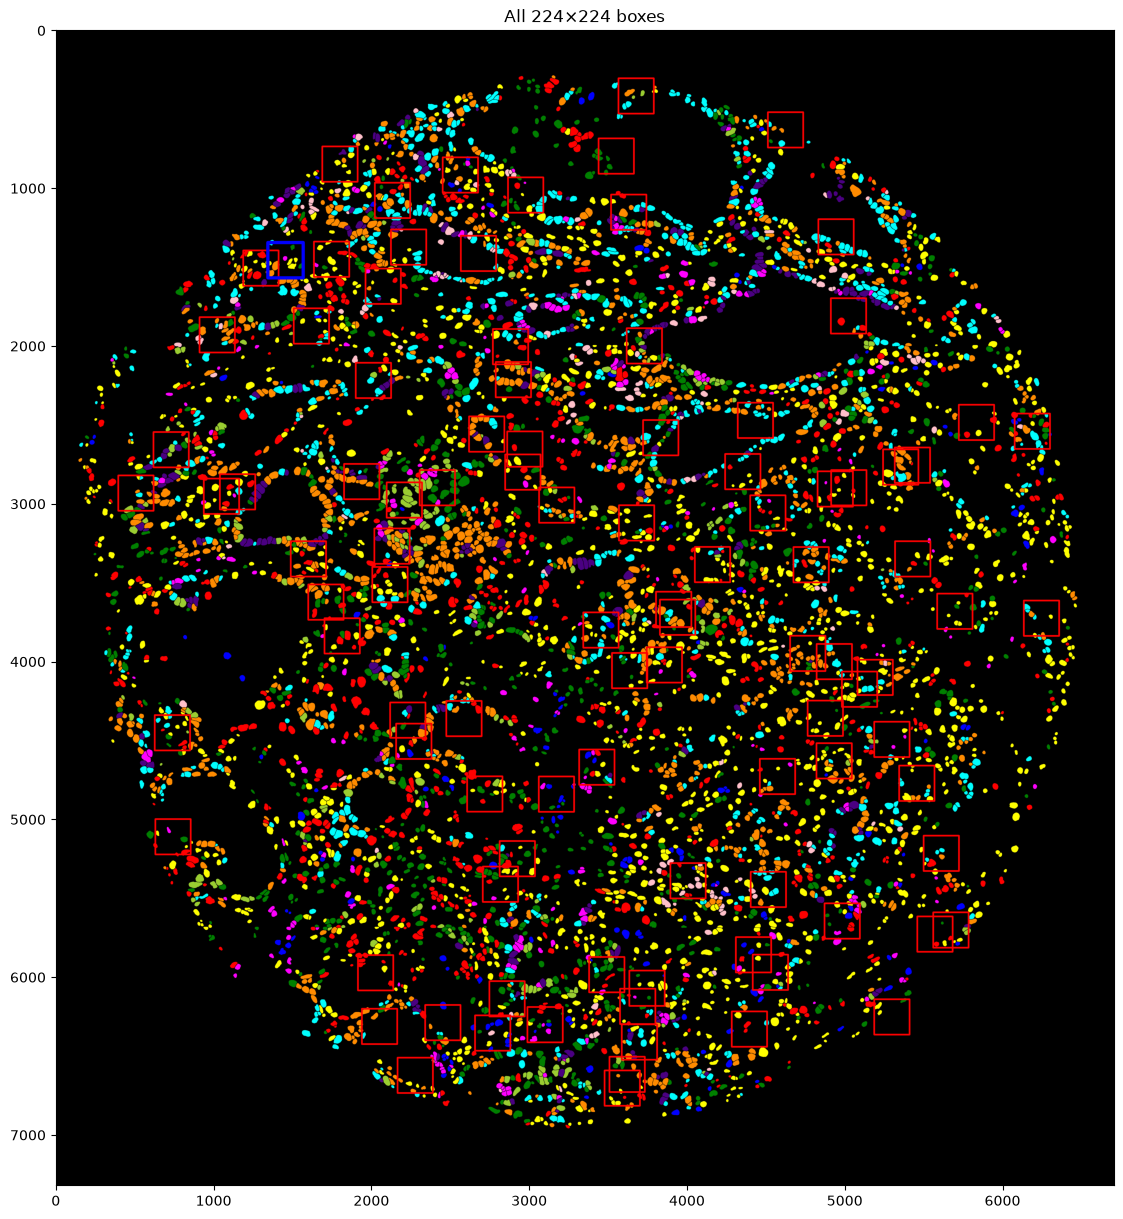

In [93]:
import cv2
path2 = 'Nimbus-Inference/templates/data/real_dataset/pixie/real_cell_output_dir_generic/cell_masks'
minx = 1344
miny = 1344

# Find and load the image once
for tiff in os.listdir(path2):
    if tiff.startswith('TMA14_60'):
        print("Found file")
        img = cv2.imread(os.path.join(path2, tiff), cv2.IMREAD_UNCHANGED)
        break

rgb = label2rgb(img, bg_label=0)

for i in points:
    x = i[0]
    y = i[1]
    cv2.rectangle(
        rgb,
        (int(x), int(y)),
        (int(x+224), int(y+224)),
        (1, 0, 0),     # red in float RGB
        10
    )
    
cv2.rectangle(
        rgb,
        (int(min_x), int(min_y)),
        (int(min_x+224), int(min_y+224)),
        (0, 0, 1),     # red in float RGB
        20
    )

plt.figure(figsize=(15,15))
plt.imshow(rgb)
plt.axis('on')
plt.title('All 224×224 boxes')
plt.show()